### Inferência Causal

*PSI e mercado de trabalho formal*


Regressão DiD


**Pergunta:** municípios mais expostos ao Finame *antes* do PSI cresceram mais (emprego e massa salarial) *depois* do programa?

### Pacotes & Imports

In [2]:
%pip install pandas numpy scipy statsmodels linearmodels matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# --- Manipulação de dados ---
import numpy as np
import pandas as pd

# --- Estatística e testes de hipótese ---
from scipy import stats                      # testes t, qui-quadrado, normalidade, etc.

# --- Regressões (MQO, DiD, efeitos fixos via fórmula) ---
import statsmodels.api as sm                 # sm.OLS, sm.Logit, sm.add_constant
import statsmodels.formula.api as smf        # smf.ols('y ~ tratado * pos + C(ano)', data=df)
from statsmodels.stats.diagnostic import het_breuschpagan   # heterocedasticidade
from statsmodels.stats.outliers_influence import variance_inflation_factor  # multicolinearidade
from statsmodels.iolib.summary2 import summary_col           # tabela comparando modelos

# --- Dados em painel (efeitos fixos/aleatórios, TWFE para DiD) ---
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from linearmodels.panel import compare as compare_panel

# --- Pareamento / escore de propensão (opcional, PSM + DiD) ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

# --- Gráficos (tendências paralelas, event study) ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configurações ---
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')

### Bases para o painel



O objetivo central é estimar esses efeitos explorando diferenças predeterminadas na exposição municipal ao Finame antes de 2009. Os objetivos específicos são: 
1. construir um painel município-ano para 2005-2013, combinando desembolsos do BNDES/Finame, indicadores da RAIS e população do IBGE; 
2. construir uma medida de exposição pré-PSI com os desembolsos do Finame de 2002-2004, anteriores ao período de análise;  
3. estimar a mudança diferencial pós-PSI segundo a exposição inicial; 
4. estimar um estudo de evento para examinar pré-tendências e a dinâmica dos efeitos; 
5. testar se o efeito cresce com o nível de exposição, por meio de uma especificação por faixas de exposição.


### DF_FINAME

In [5]:
df_finame = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\desembolsos-mensais_Finame.xlsx", sheet_name='sheet_1')

In [6]:
df_finame.head()

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,1995.0000,1.0000,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO,BARRA DO BUGRES,5101704.0000,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,4521720.3700
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1995.0000,1.0000,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,NORTE,AMAZONAS,NOVO AIRAO,1303205.0000,COMﾉRCIO E SERVIﾇOS,TRANSPORTE AQUAVIﾁRIO,INFRAESTRUTURA,OUTROS TRANSPORTES,2099499.9900


Células vazias e entrega de números inteiros em formato de decimais

Limpar a coluna


contar o que está vazio

In [7]:
df_finame = df_finame.dropna(subset=["municipio_codigo"])

df_finame[["ano", "mes", "municipio_codigo"]].isna().sum()

ano                 0
mes                 0
municipio_codigo    0
dtype: int64

In [8]:
for col in ["ano", "mes", "municipio_codigo"]:
    df_finame[col] = df_finame[col].astype(int)

In [9]:
df_finame

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO,BARRA DO BUGRES,5101704,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,4521720.3700
4,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,NORTE,AMAZONAS,NOVO AIRAO,1303205,COMﾉRCIO E SERVIﾇOS,TRANSPORTE AQUAVIﾁRIO,INFRAESTRUTURA,OUTROS TRANSPORTES,2099499.9900
5,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO DO SUL,DOURADOS,5003702,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,2064969.2400
6,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,SUDESTE,SAO PAULO,MOGI DAS CRUZES,3530607,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,2058083.2900
7,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,SUDESTE,SAO PAULO,SAO PAULO,3550308,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,1892247.4100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367837,2026,3,INDIRETA,BNDES FINAME,MODERFROTA,NﾃO,PEQUENA,SUL,PARANA,JURANDA,4112959,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203480.0000
367838,2026,3,INDIRETA,BNDES FINAME,MATERIAIS INDUSTRIALIZADOS,NﾃO,MﾉDIA,SUDESTE,ESPIRITO SANTO,SERRA,3205002,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO E SERVIﾇOS,203330.6400
367839,2026,3,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUL,SANTA CATARINA,ROMELANDIA,4215208,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203202.0000
367840,2026,3,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUDESTE,ESPIRITO SANTO,COLATINA,3201506,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203000.0000


### Df_PSI

In [10]:
df_PSI = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\desembolsos-mensais_PSI.xlsx", sheet_name='desembolsos-mensais_PSI')

df_PSI

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,2009,8,DIRETA,BNDES FINEM,PSI - BK - Demais Itens,N鬃,GRANDE,NORTE,RONDONIA,PORTO VELHO,1100205,IND湒TRIA DE TRANSFORMAO,MINERAL N鬃 MET簇ICO,INDUSTRIA,OUTRAS,17000000.0000
1,2009,8,DIRETA,BNDES FINEM,PSI - BK - Demais Itens,N鬃,GRANDE,CENTRO OESTE,MATO GROSSO,NOBRES,5105903,IND湒TRIA DE TRANSFORMAO,MINERAL N鬃 MET簇ICO,INDUSTRIA,OUTRAS,8000000.0000
2,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,GRANDE,SUDESTE,RIO DE JANEIRO,RIO DE JANEIRO,3304557,COM仂CIO E SERVIS,CONSTRUO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,5061388.7500
3,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,GRANDE,SUL,PARANA,CURITIBA,4106902,COM仂CIO E SERVIS,CONSTRUO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,2501578.0000
4,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,MICRO,CENTRO OESTE,GOIAS,RIO VERDE,5218805,AGROPECU糠IA,AGROPECU糠IA,AGROPECU糠IA,AGROPECU糠IA,2429100.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
275645,2018,1,INDIRETA,BNDES AUTOM糞ICO,PSI - Inova誽o,SIM,PEQUENA,SUDESTE,MINAS GERAIS,BELO HORIZONTE,3106200,COM仂CIO E SERVIS,INFORMAO E COMUNICAO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,230987.1900
275646,2018,2,INDIRETA,BNDES AUTOM糞ICO,PSI - Inova誽o,SIM,M厂IA,SUL,PARANA,ARAUCARIA,4101804,IND湒TRIA DE TRANSFORMAO,MADEIRA,INDUSTRIA,OUTRAS,730718.0000
275647,2018,8,INDIRETA,BNDES AUTOM糞ICO,PSI - Inova誽o,SIM,M厂IA,SUL,RIO GRANDE DO SUL,ANTONIO PRADO,4300802,IND湒TRIA DE TRANSFORMAO,M紓EIS,INDUSTRIA,OUTRAS,1730409.0000
275648,2018,9,INDIRETA,BNDES AUTOM糞ICO,PSI - Inova誽o,SIM,M厂IA,SUDESTE,MINAS GERAIS,LAGOA SANTA,3137601,IND湒TRIA DE TRANSFORMAO,CELULOSE E PAPEL,INDUSTRIA,CELULOSE E PAPEL,1400000.0000


### DF_ibge_população_estimada

In [11]:
df_IBGE_pop = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\IBGE_pop_estimativa_dou_2026.xlsx", sheet_name='sheet_1')

df_IBGE_pop

,ESTIMATIVAS DA POPULAÇÃO RESIDENTE NOS MUNICÍPIOS BRASILEIROS COM DATA DE REFERÊNCIA EM 1º DE JULHO DE 2026,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,UF,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO,POPULAÇÃO ESTIMADA
1,RO,11,00015,Alta Floresta D'Oeste,22724
2,RO,11,00023,Ariquemes,109731
3,RO,11,00031,Cabixi,5640
4,RO,11,00049,Cacoal,98884
...,...,...,...,...,...
5569,GO,52,22203,Vila Boa,4106
5570,GO,52,22302,Vila Propício,6073
5571,DF,53,00108,Brasília,3009996
5572,NaN,NaN,NaN,NaN,NaN


.copy()

Tornando independente e tudo se altera sem mexer na variavél anterior

In [ ]:
df_ibge = df_IBGE_pop.copy()

In [ ]:
df_ibge.drop(index=df_ibge.index[0], inplace=True)

In [ ]:
df_ibge.drop(index=df_ibge.index[-1], inplace=True)

In [ ]:
df_ibge.rename(columns={"ESTIMATIVAS DA POPULAÇÃO RESIDENTE NOS MUNICÍPIOS BRASILEIROS COM DATA DE REFERÊNCIA EM 1º DE JULHO DE 2026":"UF",
                   "Unnamed: 1": "COD.1",
                   "Unnamed: 2": "COD.2",
                   "Unnamed: 3": "Municipios",
                   "Unnamed: 4": "População estimada"
                     }, inplace=True)

In [ ]:
df_ibge.columns.tolist()

['UF', 'COD.1', 'COD.2', 'Municipios', 'População estimada']

In [ ]:
# # df_ibge.pd.to_numeric(df_ibge['COD.1'], errors='coerce')

# df_ibge['COD.1'].astype(float)

In [ ]:
df_ibge.dtypes

UF                       str
COD.1                 object
COD.2                 object
Municipios               str
População estimada    object
dtype: object

In [ ]:
# 1) remove a linha NaN e o rodapé "Fonte:"
df_ibge = df_ibge[
    df_ibge["COD.1"].notna() &
    df_ibge["COD.2"].notna()
].copy()

df_ibge = df_ibge[
    ~df_ibge["COD.1"].astype(str).str.upper().str.startswith("FONTE", na=False)
].copy()

df_ibge = df_ibge.reset_index(drop=True)

# 2) agora sim, concatena e converte
df_ibge["id_municipio"] = (
    df_ibge["COD.1"].astype(str).str.zfill(2)
    + df_ibge["COD.2"].astype(str).str.zfill(5)
).astype(int)

In [ ]:
df_ibge

,UF,COD.1,COD.2,Municipios,População estimada,id_municipio
0,RO,11,00015,Alta Floresta D'Oeste,22724,1100015
1,RO,11,00023,Ariquemes,109731,1100023
2,RO,11,00031,Cabixi,5640,1100031
3,RO,11,00049,Cacoal,98884,1100049
4,RO,11,00056,Cerejeiras,16957,1100056
...,...,...,...,...,...,...
5566,GO,52,22005,Vianópolis,15808,5222005
5567,GO,52,22054,Vicentinópolis,9271,5222054
5568,GO,52,22203,Vila Boa,4106,5222203
5569,GO,52,22302,Vila Propício,6073,5222302


### df_ipca

In [12]:
df_ipca = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\IPCA_STP-20261019203512642.xlsx", sheet_name='IPCA')

df_ipca

,Data,IPCA - Var. % mensal
0,2000-01-01,0.6200
1,2000-02-01,0.1300
2,2000-03-01,0.2200
3,2000-04-01,0.4200
4,2000-05-01,0.0100
...,...,...
175,2014-08-01,0.2500
176,2014-09-01,0.5700
177,2014-10-01,0.4200
178,2014-11-01,0.5100


### df_ibge_pib_municipal

In [13]:
df_pib_munic_2002_2009 = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\PIB dos Municípios - base de dados 2002-2009.xlsx", sheet_name='PIB_dos_Municípios')

df_pib_munic_2002_2009

,Ano,Código da Grande Região,Nome da Grande Região,Código da Unidade da Federação,UF,NOME UF,Código do Município,Nome do Município,Código da Região Rural,Nome da Região Rural,Região rural (segundo classificação do núcleo),Amazônia Legal,Semiárido,"Valor adicionado bruto da Agropecuária, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto da Indústria,\na preços correntes\n(R$ 1.000)","Valor adicionado bruto dos Serviços,\na preços correntes \n- exceto Administração, defesa, educação e saúde públicas e seguridade social\n(R$ 1.000)","Valor adicionado bruto da Administração, defesa, educação e saúde públicas e seguridade social, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto total, \na preços correntes\n(R$ 1.000)","Impostos, líquidos de subsídios, sobre produtos, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto per capita, \na preços correntes\n(R$ 1,00)"
0,2002,1,Norte,11,RO,Rondônia,1100015,Alta Floresta D'Oeste,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,27013.2230,9376.8710,24651.1130,42700.5230,103741.7290,7549.2660,111290.9950,4047.8300
1,2002,1,Norte,11,RO,Rondônia,1100023,Ariquemes,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,28590.1780,99922.9360,161851.5490,116562.1820,406926.8450,42665.9720,449592.8160,5667.3700
2,2002,1,Norte,11,RO,Rondônia,1100031,Cabixi,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,10883.8010,1961.9070,5128.8760,11925.0010,29899.5850,1867.9350,31767.5200,4246.9900
3,2002,1,Norte,11,RO,Rondônia,1100049,Cacoal,5105,Região Rural do Centro Sub-regional de Vilhena...,Região Rural de Centro Sub-regional,Sim,Não,32810.3760,98292.7640,175748.7030,117968.3030,424820.1460,49622.9510,474443.0970,6353.2700
4,2002,1,Norte,11,RO,Rondônia,1100056,Cerejeiras,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,11283.7930,6651.4750,25306.0090,27731.3660,70972.6430,8200.9710,79173.6140,4442.4700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44496,2009,5,Centro-oeste,52,GO,Goiás,5222005,Vianópolis,5204,Região Rural da Metrópole Nacional de Brasília,Região Rural de Metrópole Nacional,Não,Não,53529.0850,14813.1680,58617.5850,26216.1580,153175.9960,11160.3410,164336.3370,12807.7600
44497,2009,5,Centro-oeste,52,GO,Goiás,5222054,Vicentinópolis,5206,Região Rural do Centro Sub-regional de Itumbiara,Região Rural de Centro Sub-regional,Não,Não,63465.0400,11101.4180,38070.9060,13974.0180,126611.3820,6819.0300,133430.4130,21898.9700
44498,2009,5,Centro-oeste,52,GO,Goiás,5222203,Vila Boa,5203,Região Rural do Centro de Zona de Campos Belos,Região Rural de Centro de zona,Não,Não,25391.5200,12652.8350,19921.0140,11463.2990,69428.6690,3938.7130,73367.3810,16026.0800
44499,2009,5,Centro-oeste,52,GO,Goiás,5222302,Vila Propício,5202,Região Rural do Centro Sub-regional de Anápolis,Região Rural de Centro Sub-regional,Não,Não,49814.2180,26168.4280,16793.2110,11847.7400,104623.5970,2501.7940,107125.3910,19989.8100


In [15]:
df_pib_munic_2010_2023 = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\PIB dos Municípios - base de dados 2010-2023.xlsx", sheet_name='PIB dos Municípios')

df_pib_munic_2010_2023

,Ano,Código da Grande Região,Nome da Grande Região,Código da Unidade da Federação,Sigla da Unidade da Federação,Nome da Unidade da Federação,Código do Município,Nome do Município,Região Metropolitana,Código da Mesorregião,Nome da Mesorregião,Código da Microrregião,Nome da Microrregião,Código da Região Geográfica Imediata,Nome da Região Geográfica Imediata,Município da Região Geográfica Imediata,Código da Região Geográfica Intermediária,Nome da Região Geográfica Intermediária,Município da Região Geográfica Intermediária,Código Concentração Urbana,Nome Concentração Urbana,Tipo Concentração Urbana,Código Arranjo Populacional,Nome Arranjo Populacional,Hierarquia Urbana,Hierarquia Urbana (principais categorias),Código da Região Rural,Nome da Região Rural,Região rural (segundo classificação do núcleo),Amazônia Legal,Semiárido,Cidade-Região de São Paulo,"Valor adicionado bruto da Agropecuária, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto da Indústria,\na preços correntes\n(R$ 1.000)","Valor adicionado bruto dos Serviços,\na preços correntes \n- exceto Administração, defesa, educação e saúde públicas e seguridade social\n(R$ 1.000)","Valor adicionado bruto da Administração, defesa, educação e saúde públicas e seguridade social, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto total, \na preços correntes\n(R$ 1.000)","Impostos, líquidos de subsídios, sobre produtos, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto per capita, \na preços correntes\n(R$ 1,00)",Atividade com maior valor adicionado bruto,Atividade com segundo maior valor adicionado bruto,Atividade com terceiro maior valor adicionado bruto
0,2010,1,Norte,11,RO,Rondônia,1100015,Alta Floresta D'Oeste,NaN,1102,Leste Rondoniense,11006,Cacoal,110005,Cacoal,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Local,Centro Local,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,69260.3910,16118.5340,62496.1850,93244.6560,241119.7670,20957.1110,262076.8780,10731.1800,"Administração, defesa, educação e saúde públic...","Pecuária, inclusive apoio à pecuária",Demais serviços
1,2010,1,Norte,11,RO,Rondônia,1100023,Ariquemes,NaN,1102,Leste Rondoniense,11003,Ariquemes,110002,Ariquemes,Polo,1101,Porto Velho,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Sub-Regional A,Centro Sub-Regional,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,73711.6430,287138.5850,494946.2670,343867.7310,1199664.2270,165029.5530,1364693.7800,15103.8600,"Administração, defesa, educação e saúde públic...",Demais serviços,Comércio e reparação de veículos automotores e...
2,2010,1,Norte,11,RO,Rondônia,1100031,Cabixi,NaN,1102,Leste Rondoniense,11008,Colorado do Oeste,110006,Vilhena,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Local,Centro Local,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,24300.8220,3252.5060,12677.2100,25170.2350,65400.7720,4210.3420,69611.1140,11033.6200,"Administração, defesa, educação e saúde públic...","Pecuária, inclusive apoio à pecuária",Demais serviços
3,2010,1,Norte,11,RO,Rondônia,1100049,Cacoal,NaN,1102,Leste Rondoniense,11006,Cacoal,110005,Cacoal,Polo,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Capital Regional C,Capital Regional,5105,Região Rural do Centro Sub-regional de Vilhena...,Região Rural de Centro Sub-regional,Sim,Não,Não,95259.2030,182051.5370,465447.3250,298454.3090,1041212.3740,145281.7170,1186494.0910,15095.1500,"Administração, defesa, educação e saúde públic...",Demais serviços,Comércio e reparação de veículos automotores e...
4,2010,1,Norte,11,RO,Rondônia,1100056,Cerejeiras,NaN,1102,Leste Rondoniense,11008,Colorado do Oeste,110006,Vilhena,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro de Zona B,Centro de Zona,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não

### df_RAIS_emprego_salario

In [17]:
df_rais = pd.read_excel(r"C:\Users\DESKTOP\Desktop\Script -  Avaliação de impacto\dados_base's\rais_empr_remuner_2000_2014.xlsx", sheet_name='RAIS')
df_rais

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
0,2001,IGNORADO,NaN,NaN,39,0.5897,41.2308,0.4103,0.0000,0.0000,0.0000,NaN,807.8531,833.0259
1,2002,IGNORADO,NaN,NaN,54,0.5000,37.8704,0.5000,0.0000,0.0000,0.0000,NaN,802.8307,782.9515
2,2003,IGNORADO,NaN,NaN,2,0.5000,25.5000,0.5000,0.0000,0.0000,0.0000,NaN,451.7350,569.8800
3,2004,IGNORADO,NaN,NaN,1,0.0000,28.0000,1.0000,0.0000,0.0000,0.0000,NaN,403.3200,413.3200
4,2005,IGNORADO,NaN,NaN,5,0.4000,35.4000,0.6000,0.0000,0.0000,0.0000,NaN,1231.6060,652.6220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83304,2010,DF,5300108.0000,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83305,2011,DF,5300108.0000,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83306,2012,DF,5300108.0000,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370
83307,2013,DF,5300108.0000,NaN,1302284,0.6339,35.5421,0.3661,0.0223,0.2341,0.2564,NaN,3782.9309,4097.1058


In [ ]:
df_rais.columns.tolist()

['ano',
 'sigla_uf',
 'id_municipio',
 'subsetor_ibge',
 'emprego_3112',
 'prop_homens',
 'idade_media',
 'prop_mulheres',
 'prop_preta',
 'prop_parda',
 'prop_negra',
 'valor_salario_contratual',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']

In [ ]:
df_rais = df_rais.dropna(subset=["id_municipio"])

# rais[["id_municipio", "valor_salario_contratual", "valor_remuneracao_media",  "valor_remuneracao_dezembro"]].isna().sum()

In [ ]:
for col in ["id_municipio"]:
    df_rais[col] = df_rais[col].astype(int)

df_rais[col].dtypes


dtype('int64')

In [ ]:
# rais = rais[['ano',
#              'sigla_uf',
#              'id_municipio',
#              'emprego_3112',
#              'prop_homens',
#              'idade_media',
#              'prop_mulheres',
#              'prop_preta',
#              'prop_parda',
#              'prop_negra',
#              'valor_remuneracao_media',
#              'valor_remuneracao_dezembro']]

df_rais.reset_index(drop=True, inplace=True)

df_rais

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
0,2000,RO,1100015,NaN,1196,0.5677,31.1931,0.4323,0.0000,0.0000,0.0000,NaN,287.4081,290.0647
1,2001,RO,1100015,NaN,1185,0.5789,31.6574,0.4211,0.0000,0.0000,0.0000,NaN,330.5743,323.1142
2,2002,RO,1100015,NaN,1440,0.5785,32.2160,0.4215,0.0000,0.0000,0.0000,NaN,438.4699,409.4442
3,2003,RO,1100015,NaN,1629,0.5856,32.4205,0.4144,0.0000,0.0000,0.0000,NaN,473.1530,503.8662
4,2004,RO,1100015,NaN,1610,0.6050,32.2075,0.3950,0.0000,0.0000,0.0000,NaN,520.5894,533.4424
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83297,2010,DF,5300108,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83298,2011,DF,5300108,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83299,2012,DF,5300108,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370
83300,2013,DF,5300108,NaN,1302284,0.6339,35.5421,0.3661,0.0223,0.2341,0.2564,NaN,3782.9309,4097.1058


In [ ]:
# rais["id_municipio"] = rais["id_municipio"].astype(int)

### 1. construir um painel município-ano para 2005-2013, combinando desembolsos do BNDES/Finame, indicadores da RAIS e população do IBGE; 

In [18]:
df_finame.columns = df_finame.columns.str.strip()
df_finame.columns.tolist()

['ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'uf',
 'municipio',
 'municipio_codigo',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 'desembolsos_reais']

In [19]:
df_finame_filtro_2013 = df_finame[(df_finame.ano >= 2005) & (df_finame.ano <= 2013)]

selecionado só as colunas de interesse do df_finame

In [20]:
df_finame_filtro_2013 = df_finame_filtro_2013[["ano",
                 "uf",
                "municipio", 
                 "municipio_codigo", 
                 "instrumento_financeiro",
                  "setor_cnae",                
                 "desembolsos_reais"]]

agrupando as informações por colunas selecionadas


vários agrupamentos de n informações/colunas

In [21]:
df_finame_filtro_2013 = df_finame_filtro_2013.groupby(["ano",
                            "uf",
                            "municipio", 
                            "municipio_codigo", 
                            "instrumento_financeiro",
                            "setor_cnae"  
                            ]).desembolsos_reais.sum().reset_index()


df_finame_filtro_2013 = df_finame_filtro_2013.rename(columns={"municipio_codigo": "id_municipio",
                                           "desembolsos_reais": "R$_finame"})

df_finame_filtro_2013

,ano,uf,municipio,id_municipio,instrumento_financeiro,setor_cnae,R$_finame
0,2005,ACRE,ACRELANDIA,1200013,OUTROS,AGROPECUﾁRIA,220000.0000
1,2005,ACRE,BRASILEIA,1200104,OUTROS,COMﾉRCIO E SERVIﾇOS,344250.0000
2,2005,ACRE,CRUZEIRO DO SUL,1200203,OUTROS,COMﾉRCIO E SERVIﾇOS,2066310.7600
3,2005,ACRE,PLACIDO DE CASTRO,1200385,MODERFROTA,AGROPECUﾁRIA,250400.0000
4,2005,ACRE,RIO BRANCO,1200401,MODERFROTA,AGROPECUﾁRIA,264000.0000
...,...,...,...,...,...,...,...
34504,2013,TOCANTINS,ARAGUAINA,1702109,BNDES PROCAMINHONEIRO - Equalizado,COMﾉRCIO E SERVIﾇOS,1321611.8100
34505,2013,TOCANTINS,GUARAI,1709302,BNDES PROCAMINHONEIRO - Equalizado,COMﾉRCIO E SERVIﾇOS,233101.6800
34506,2013,TOCANTINS,GURUPI,1709500,BNDES PROCAMINHONEIRO - Equalizado,COMﾉRCIO E SERVIﾇOS,1611599.2800
34507,2013,TOCANTINS,PARAISO DO TOCANTINS,1716109,BK AQUISIﾇﾃO E COMERCIALIZAﾇﾃO - DEMAIS,COMﾉRCIO E SERVIﾇOS,329000.0000


In [22]:
df_finame_filtro_2013.groupby("ano")["R$_finame"].sum() / 1e5

ano
2005   100949.5216
2006   110468.2293
2007   181522.1594
2008   238850.7481
2009   130051.6247
2010    73813.4002
2011   181436.0838
2012    76838.3406
2013    12497.7693
Name: R$_finame, dtype: float64

In [23]:
df_finame_filtro_2013.dtypes

ano                         int64
uf                            str
municipio                     str
id_municipio                int64
instrumento_financeiro        str
setor_cnae                    str
R$_finame                 float64
dtype: object

In [24]:
df_finame_filtro_2013['ano'] = df_finame_filtro_2013['ano'].astype(int)

In [25]:
df_rais.columns = df_rais.columns.str.strip()
df_rais.columns.tolist()

['ano',
 'sigla_uf',
 'id_municipio',
 'subsetor_ibge',
 'emprego_3112',
 'prop_homens',
 'idade_media',
 'prop_mulheres',
 'prop_preta',
 'prop_parda',
 'prop_negra',
 'valor_salario_contratual',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']

O id_municipio serve como ponto central de conexão entre o df_finame e o df_rais, os dois tem as mesmas informações

In [26]:
df_rais_filtro_2013 = df_rais[(df_rais.ano >= 2005) & (df_rais.ano <= 2013)]


In [27]:
df_rais_filtro_2013

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
4,2005,IGNORADO,NaN,NaN,5,0.4000,35.4000,0.6000,0.0000,0.0000,0.0000,NaN,1231.6060,652.6220
5,2006,IGNORADO,NaN,NaN,6,0.3333,33.5000,0.6667,0.0000,0.0000,0.0000,NaN,1120.2583,1148.4767
6,2007,IGNORADO,NaN,NaN,4,0.7500,39.7500,0.2500,0.0000,0.0000,0.0000,NaN,1822.4250,2056.2550
12,2005,RO,1100015.0000,NaN,1715,0.6052,32.9405,0.3948,0.0000,0.0000,0.0000,NaN,586.8347,599.4465
13,2006,RO,1100015.0000,NaN,1950,0.6077,33.1185,0.3923,0.0164,0.2133,0.2297,NaN,633.0259,650.7856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83303,2009,DF,5300108.0000,NaN,1062241,0.6393,35.6629,0.3607,0.0231,0.2128,0.2359,NaN,3049.5344,3338.8355
83304,2010,DF,5300108.0000,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83305,2011,DF,5300108.0000,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83306,2012,DF,5300108.0000,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370


In [28]:
df_rais_filtro_2013.columns.tolist()

['ano',
 'sigla_uf',
 'id_municipio',
 'subsetor_ibge',
 'emprego_3112',
 'prop_homens',
 'idade_media',
 'prop_mulheres',
 'prop_preta',
 'prop_parda',
 'prop_negra',
 'valor_salario_contratual',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']

In [29]:
# df_rais_filtro_2013 = df_rais_filtro_2013[["ano",
#             "sigla_uf",
#             "id_municipio",
#             #  "municipio",
#              "emprego_3112", 
#              "valor_remuneracao_media"
#             #  ]

In [30]:
df_rais_filtro_2013.rename(columns={"sigla_uf": "uf",
                        "emprego_3112": "Qtd_empregos",
                        "valor_remuneracao_media": "Remuneracao_media"}, inplace=True)

df_rais_filtro_2013

,ano,uf,id_municipio,subsetor_ibge,Qtd_empregos,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,Remuneracao_media,valor_remuneracao_dezembro
4,2005,IGNORADO,NaN,NaN,5,0.4000,35.4000,0.6000,0.0000,0.0000,0.0000,NaN,1231.6060,652.6220
5,2006,IGNORADO,NaN,NaN,6,0.3333,33.5000,0.6667,0.0000,0.0000,0.0000,NaN,1120.2583,1148.4767
6,2007,IGNORADO,NaN,NaN,4,0.7500,39.7500,0.2500,0.0000,0.0000,0.0000,NaN,1822.4250,2056.2550
12,2005,RO,1100015.0000,NaN,1715,0.6052,32.9405,0.3948,0.0000,0.0000,0.0000,NaN,586.8347,599.4465
13,2006,RO,1100015.0000,NaN,1950,0.6077,33.1185,0.3923,0.0164,0.2133,0.2297,NaN,633.0259,650.7856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83303,2009,DF,5300108.0000,NaN,1062241,0.6393,35.6629,0.3607,0.0231,0.2128,0.2359,NaN,3049.5344,3338.8355
83304,2010,DF,5300108.0000,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83305,2011,DF,5300108.0000,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83306,2012,DF,5300108.0000,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370


In [31]:
painel = pd.merge(df_rais_filtro_2013, df_finame_filtro_2013, on=["id_municipio"], how="left")

painel.columns.tolist()

['ano_x',
 'uf_x',
 'id_municipio',
 'subsetor_ibge',
 'Qtd_empregos',
 'prop_homens',
 'idade_media',
 'prop_mulheres',
 'prop_preta',
 'prop_parda',
 'prop_negra',
 'valor_salario_contratual',
 'Remuneracao_media',
 'valor_remuneracao_dezembro',
 'ano_y',
 'uf_y',
 'municipio',
 'instrumento_financeiro',
 'setor_cnae',
 'R$_finame']

In [32]:
painel = painel[['ano_x',
                 'municipio',
                'Qtd_empregos',
                'Remuneracao_media',
                'instrumento_financeiro',
                'setor_cnae',
                'R$_finame']]

painel.rename(columns={"ano_x": "ano"
                       }, inplace=True)

painel

,ano,municipio,Qtd_empregos,Remuneracao_media,instrumento_financeiro,setor_cnae,R$_finame
0,2005,NaN,5,1231.6060,NaN,NaN,NaN
1,2006,NaN,6,1120.2583,NaN,NaN,NaN
2,2007,NaN,4,1822.4250,NaN,NaN,NaN
3,2005,ALTA FLORESTA D'OESTE,1715,586.8347,OUTROS,COMﾉRCIO E SERVIﾇOS,719780.0000
4,2005,ALTA FLORESTA D'OESTE,1715,586.8347,BK AQUISIﾇﾃO E COMERCIALIZAﾇﾃO - DEMAIS,COMﾉRCIO E SERVIﾇOS,210400.0000
...,...,...,...,...,...,...,...
324897,2013,BRASILIA,1302284,3782.9309,BK AQUISIﾇﾃO E COMERCIALIZAﾇﾃO - DEMAIS,COMﾉRCIO E SERVIﾇOS,61340750.0900
324898,2013,BRASILIA,1302284,3782.9309,BK AQUISIﾇﾃO E COMERCIALIZAﾇﾃO - DEMAIS,INDﾚSTRIA DE TRANSFORMAﾇﾃO,1006580.0000
324899,2013,BRASILIA,1302284,3782.9309,BK AQUISIﾇﾃO E COMERCIALIZAﾇﾃO ・ﾔNIBUS E CAMINHﾃO,COMﾉRCIO E SERVIﾇOS,636222.6000
324900,2013,BRASILIA,1302284,3782.9309,BNDES PROCAMINHONEIRO - Equalizado,COMﾉRCIO E SERVIﾇOS,2566255.2400


ainda não está como município-ano, pois repete diversas vezes as informações sobre o mesmo municipio -- ajustar

Serve para agregar finame no ano inteiro

In [33]:
df_finame_group_ano = df_finame_filtro_2013.groupby(['ano', 'id_municipio', 'municipio'])['R$_finame'].sum().reset_index()

In [34]:
df_finame_group_ano

,ano,id_municipio,municipio,R$_finame
0,2005,1100015,ALTA FLORESTA D'OESTE,719780.0000
1,2005,1100023,ARIQUEMES,5259940.4800
2,2005,1100031,CABIXI,314232.0000
3,2005,1100049,CACOAL,2858057.8200
4,2005,1100056,CEREJEIRAS,1755519.8200
...,...,...,...,...
18381,2013,5218805,RIO VERDE,276000.0000
18382,2013,5218904,RUBIATABA,1163956.4200
18383,2013,5220207,SAO MIGUEL DO ARAGUAIA,374377.3900
18384,2013,5220504,SERRANOPOLIS,628362.1900


In [35]:
df_rais_group_ano_1 = df_rais_filtro_2013.groupby(['ano', 'id_municipio'])['Qtd_empregos'].sum().reset_index()

In [36]:
df_rais_group_ano_2 = df_rais_filtro_2013.groupby(['ano', 'id_municipio'])['Remuneracao_media'].sum().reset_index()

In [37]:
df_rais_group_ano = pd.merge(df_rais_group_ano_1, df_rais_group_ano_2, on=["ano", "id_municipio"], how="left")

In [38]:
df_rais_group_ano

,ano,id_municipio,Qtd_empregos,Remuneracao_media
0,2005,1100015.0000,1715,586.8347
1,2005,1100023.0000,11131,636.4996
2,2005,1100031.0000,397,589.2898
3,2005,1100049.0000,10200,660.6356
4,2005,1100056.0000,1430,601.5751
...,...,...,...,...
50070,2013,5222005.0000,2105,1264.1137
50071,2013,5222054.0000,1809,1759.3279
50072,2013,5222203.0000,912,1398.7955
50073,2013,5222302.0000,924,1238.6961


In [39]:
painel_municipio_ano = pd.merge(df_rais_group_ano, df_finame_group_ano, on=["ano", "id_municipio"], how="left")

In [40]:
painel_municipio_ano.columns.tolist()

['ano',
 'id_municipio',
 'Qtd_empregos',
 'Remuneracao_media',
 'municipio',
 'R$_finame']

In [41]:
# painel_municipio_ano

In [42]:
# painel_municipio_ano = painel_municipio_ano[['ano',
#                                               'id_municipio_x',
#                                                 'municipio',
#                                                 'Qtd_empregos',
#                                                 'Remuneracao_media',
#                                                 'R$_finame']]


painel_municipio_ano.rename(columns={"id_municipio_x":"id_municipio"})

,ano,id_municipio,Qtd_empregos,Remuneracao_media,municipio,R$_finame
0,2005,1100015.0000,1715,586.8347,ALTA FLORESTA D'OESTE,719780.0000
1,2005,1100023.0000,11131,636.4996,ARIQUEMES,5259940.4800
2,2005,1100031.0000,397,589.2898,CABIXI,314232.0000
3,2005,1100049.0000,10200,660.6356,CACOAL,2858057.8200
4,2005,1100056.0000,1430,601.5751,CEREJEIRAS,1755519.8200
...,...,...,...,...,...,...
50070,2013,5222005.0000,2105,1264.1137,NaN,NaN
50071,2013,5222054.0000,1809,1759.3279,NaN,NaN
50072,2013,5222203.0000,912,1398.7955,NaN,NaN
50073,2013,5222302.0000,924,1238.6961,NaN,NaN


In [43]:
# painel_municipio_ano

não posso remover os municipios que não tiveram exposição ao final, pois eles fazem parte importante do trabalho, ok??

In [44]:
# painel_municipio_ano = painel_municipio_ano.dropna(subset=['municipio','R$_finame'])

In [45]:
painel_municipio_ano['R$_finame'] = painel_municipio_ano['R$_finame'].fillna(0)
# painel_municipio_ano['municipio'] = painel_municipio_ano['municipio'].fillna('Desconhecido')

In [46]:
painel_municipio_ano

,ano,id_municipio,Qtd_empregos,Remuneracao_media,municipio,R$_finame
0,2005,1100015.0000,1715,586.8347,ALTA FLORESTA D'OESTE,719780.0000
1,2005,1100023.0000,11131,636.4996,ARIQUEMES,5259940.4800
2,2005,1100031.0000,397,589.2898,CABIXI,314232.0000
3,2005,1100049.0000,10200,660.6356,CACOAL,2858057.8200
4,2005,1100056.0000,1430,601.5751,CEREJEIRAS,1755519.8200
...,...,...,...,...,...,...
50070,2013,5222005.0000,2105,1264.1137,NaN,0.0000
50071,2013,5222054.0000,1809,1759.3279,NaN,0.0000
50072,2013,5222203.0000,912,1398.7955,NaN,0.0000
50073,2013,5222302.0000,924,1238.6961,NaN,0.0000


In [47]:
painel_municipio_ano.to_excel('painel_munic_ano.xlsx', index=False)

### Refazendo painel porém com IBGE como central

In [68]:
painel_final = df_rais_group_ano.copy()
painel_final = df_finame_group_ano.copy()
painel_final = df_ibge.copy()

In [69]:
df_painel_final1 = pd.merge(df_rais_group_ano, df_finame_group_ano, on=["ano", "id_municipio"], how="left")

df_painel_final1

,ano,id_municipio,Qtd_empregos,Remuneracao_media,municipio,R$_finame
0,2005,1100015.0000,1715,586.8347,ALTA FLORESTA D'OESTE,719780.0000
1,2005,1100023.0000,11131,636.4996,ARIQUEMES,5259940.4800
2,2005,1100031.0000,397,589.2898,CABIXI,314232.0000
3,2005,1100049.0000,10200,660.6356,CACOAL,2858057.8200
4,2005,1100056.0000,1430,601.5751,CEREJEIRAS,1755519.8200
...,...,...,...,...,...,...
50070,2013,5222005.0000,2105,1264.1137,NaN,NaN
50071,2013,5222054.0000,1809,1759.3279,NaN,NaN
50072,2013,5222203.0000,912,1398.7955,NaN,NaN
50073,2013,5222302.0000,924,1238.6961,NaN,NaN


In [70]:
# 2) + IBGE (chave: só id_municipio — o IBGE não tem ano)
df_painel_final = pd.merge(
    df_painel_final1,
    df_ibge,
    on=["id_municipio"],
    how="left"
)

In [71]:
painel_final

,UF,COD.1,COD.2,Municipios,População estimada,id_municipio
0,RO,11,00015,Alta Floresta D'Oeste,22724,1100015
1,RO,11,00023,Ariquemes,109731,1100023
2,RO,11,00031,Cabixi,5640,1100031
3,RO,11,00049,Cacoal,98884,1100049
4,RO,11,00056,Cerejeiras,16957,1100056
...,...,...,...,...,...,...
5566,GO,52,22005,Vianópolis,15808,5222005
5567,GO,52,22054,Vicentinópolis,9271,5222054
5568,GO,52,22203,Vila Boa,4106,5222203
5569,GO,52,22302,Vila Propício,6073,5222302


In [131]:
# painel_final = pd.merge(df_rais_group_ano, df_finame_group_ano, df_ibge, on=["ano", "id_municipio"], how="left")


# painel_municipio_ano.columns.tolist()



# painel_municipio_ano.rename(columns={"id_municipio_x":"id_municipio"})



# painel_municipio_ano['R$_finame'] = painel_municipio_ano['R$_finame'].fillna(0)

### Painel final

In [123]:
ano = pd.DataFrame({
    "ano": [2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]
})

In [127]:
painel_final_merge_ibge = pd.merge(
    df_ibge,
    ano,
    how="cross"
)

painel_final_merge_ibge

,UF,COD.1,COD.2,Municipios,População estimada,id_municipio,ano
0,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2005
1,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2006
2,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2007
3,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2008
4,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2009
...,...,...,...,...,...,...,...
50134,DF,53,00108,Brasília,3009996,5300108,2009
50135,DF,53,00108,Brasília,3009996,5300108,2010
50136,DF,53,00108,Brasília,3009996,5300108,2011
50137,DF,53,00108,Brasília,3009996,5300108,2012


In [128]:
painel_final_merge_rais = pd.merge(
    painel_final_merge_ibge,
    df_rais_group_ano,
    on=["ano", "id_municipio"],
    how="left",
    validate="one_to_one"
)

painel_final_merge_rais

,UF,COD.1,COD.2,Municipios,População estimada,id_municipio,ano,Qtd_empregos,Remuneracao_media
0,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2005,1715.0000,586.8347
1,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2006,1950.0000,633.0259
2,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2007,2024.0000,692.4558
3,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2008,2036.0000,762.8247
4,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2009,2224.0000,875.2053
...,...,...,...,...,...,...,...,...,...
50134,DF,53,00108,Brasília,3009996,5300108,2009,1062241.0000,3049.5344
50135,DF,53,00108,Brasília,3009996,5300108,2010,1099832.0000,3274.0976
50136,DF,53,00108,Brasília,3009996,5300108,2011,1156908.0000,3417.8013
50137,DF,53,00108,Brasília,3009996,5300108,2012,1181649.0000,3639.5494


In [ ]:
painel_final_merge_finame = pd.merge(
    painel_final_merge_rais,
    df_finame_group_ano,
    on=["ano", "id_municipio"],
    how="left",
    validate="one_to_one"
)

painel_final_merge_finame

,UF,COD.1,COD.2,Municipios,População estimada,id_municipio,ano,Qtd_empregos,Remuneracao_media,municipio,R$_finame
0,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2005,1715.0000,586.8347,ALTA FLORESTA D'OESTE,719780.0000
1,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2006,1950.0000,633.0259,NaN,NaN
2,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2007,2024.0000,692.4558,ALTA FLORESTA D'OESTE,450205.0000
3,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2008,2036.0000,762.8247,ALTA FLORESTA D'OESTE,2213442.3000
4,RO,11,00015,Alta Floresta D'Oeste,22724,1100015,2009,2224.0000,875.2053,ALTA FLORESTA D'OESTE,652396.8000
...,...,...,...,...,...,...,...,...,...,...,...
50134,DF,53,00108,Brasília,3009996,5300108,2009,1062241.0000,3049.5344,BRASILIA,164677655.9500
50135,DF,53,00108,Brasília,3009996,5300108,2010,1099832.0000,3274.0976,BRASILIA,50534264.2400
50136,DF,53,00108,Brasília,3009996,5300108,2011,1156908.0000,3417.8013,BRASILIA,153967788.4900
50137,DF,53,00108,Brasília,3009996,5300108,2012,1181649.0000,3639.5494,BRASILIA,65843639.9300


In [ ]:
# print("Dimensão:", painel_final.shape)

# print("Municípios:", painel_final["id_municipio"].nunique())

# print("Anos:", painel_final["ano"].nunique())

# print("Duplicações:", painel_final.duplicated(
#     subset=["ano", "id_municipio"]
# ).sum())

Dimensão: (50139, 11)
Municípios: 5571
Anos: 9
Duplicações: 0


In [133]:
# painel_final_merge_finame.rename(columns={"municipio": "nome_municipio",
#                                             "Qtd_empregos_x": "Qtd_empregos",
#                                             "Remuneracao_media_x": "Remuneracao_media",
#                                             })

In [134]:
painel_final = painel_final_merge_finame

In [135]:
print("Dimensão:", painel_final.shape)

print("Municípios:", painel_final["id_municipio"].nunique())

print("Anos:", painel_final["ano"].nunique())

print("Duplicações:", painel_final.duplicated(
    subset=["ano", "id_municipio"]
).sum())

print("\nValores ausentes:")
print(painel_final.isna().sum())

Dimensão: (50139, 11)
Municípios: 5571
Anos: 9
Duplicações: 0

Valores ausentes:
UF                        0
COD.1                     0
COD.2                     0
Municipios                0
População estimada        0
id_municipio              0
ano                       0
Qtd_empregos             64
Remuneracao_media        64
municipio             31753
R$_finame             31753
dtype: int64


In [136]:
painel_final.groupby("ano")["R$_finame"].agg(
    registros="count",
    ausentes=lambda x: x.isna().sum(),
    desembolso_total="sum"
)

,registros,ausentes,desembolso_total
ano,,,
2005,2005,3566,10094952161.6200
2006,1953,3618,11046822931.5500
2007,2306,3265,18152215940.5000
2008,2557,3014,23885074810.6100
2009,2413,3158,13005162474.2200
2010,2029,3542,7381340018.9200
2011,2565,3006,18143608378.3500
2012,1814,3757,7683834064.7500
2013,744,4827,1249776931.1200


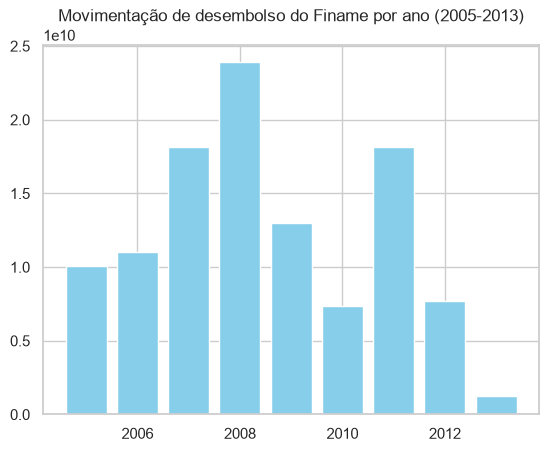

In [139]:
valores_grafico = painel_final.groupby("ano")["R$_finame"].sum().reset_index()

# Criar o gráfico de barras
plt.bar(valores_grafico["ano"], valores_grafico["R$_finame"], color='skyblue')

# Adicionar títulos e rótulos
plt.title('Movimentação de desembolso do Finame por ano (2005-2013)')

# Exibir o gráfico
plt.show()
